In [ ]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys

scripts_path = "/local/scratch/lslagter/MSC_project/STRW-MSC/scripts"
scripts_path = "/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts"
from pathlib import Path

scripts_path = Path.cwd().parents[1]
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

import Config
from Config import (
    CATALOGUE_JEROEN,
    POSITIONS_F115W,
    GAIA_CATALOGUE,
    MPLSTYLE,
    SB_PARAM_DIR,
    PHOT_DIR,
    PLOTS_DIR,
    LEVEL2_DIR,
    LEVEL3_DIR,
    STARBUG2_BIN,
)
import phot_toolkit as PTK
import photometric_pipeline as PPL
import plot_toolkit as PLOT

import numpy as np
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from matplotlib.colors import to_rgb
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import astropy.units as u

if MPLSTYLE.exists():
    plt.style.use(str(MPLSTYLE))

working_directory = f"{LEVEL2_DIR}/mastDownload/JWST"
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory=working_directory)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black
Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


Set OBSGEO-B to   -37.870811 from OBSGEO-[XYZ].
Set OBSGEO-H to 1740803710.190 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -37.870811 from OBSGEO-[XYZ].
Set OBSGEO-H to 1740803710.190 from OBSGEO-[XYZ]'.


Initializing for F115W...
Skipping starbug2 run
Fractional <2.0 Emag 0.9027725028484618
/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/Photometry/Aperture



KeyboardInterrupt



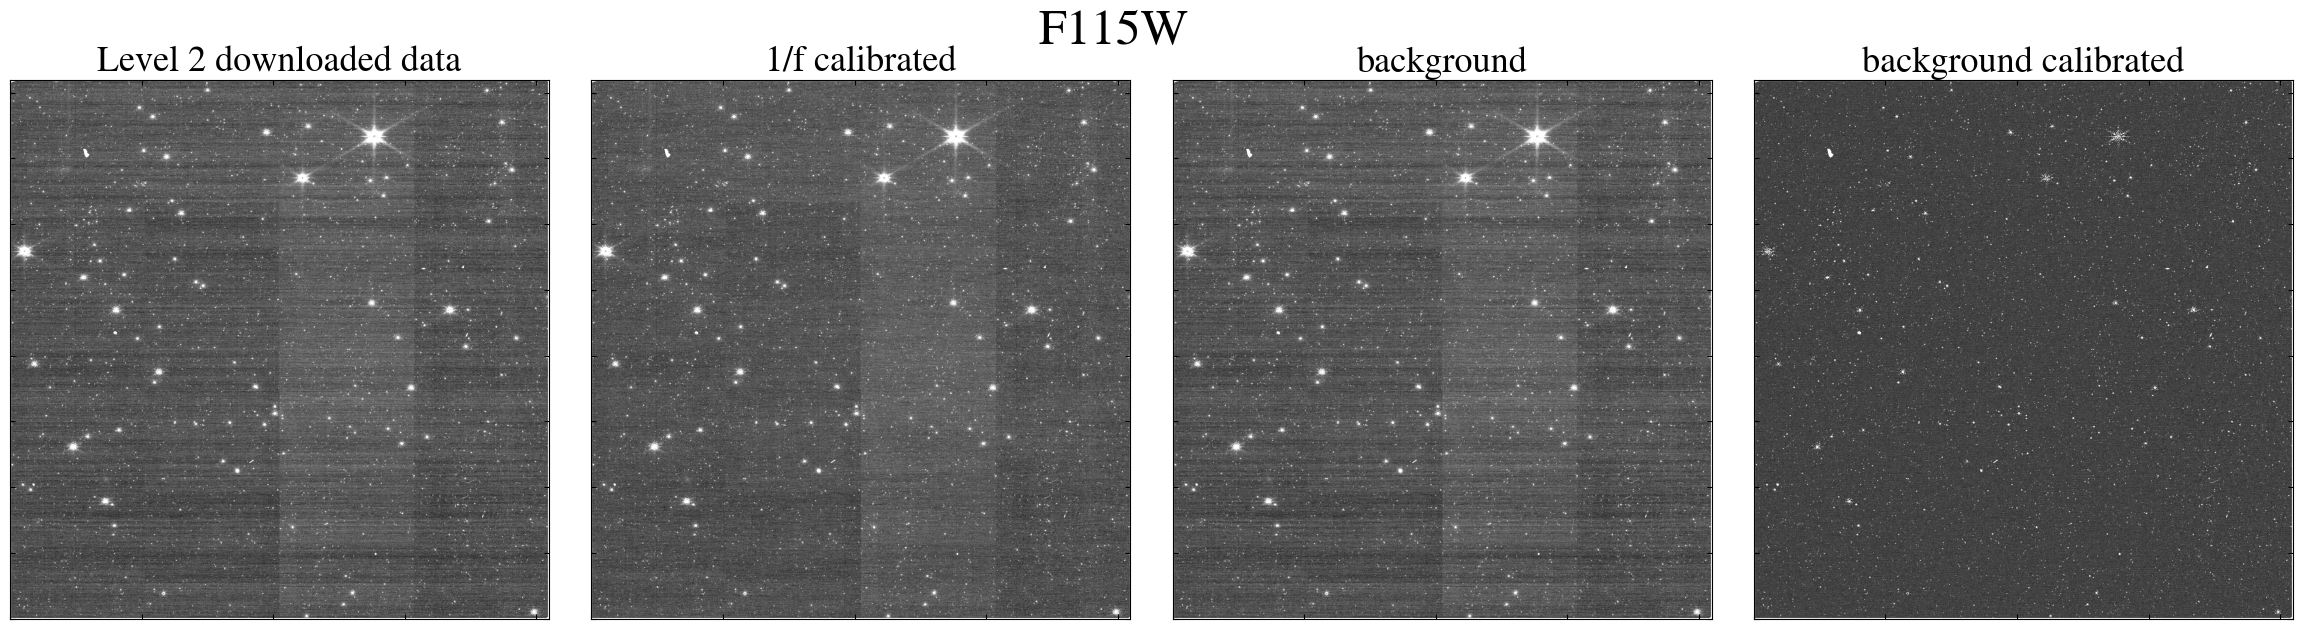

In [2]:
IMAGE_INDEX = 90
PHOTOMETRIC_pipeline.run_pipeline_single(
    IMAGE_INDEX=IMAGE_INDEX,
    detection_sigma=2.0,
    overwrite_always_run=False,
    save=True,
    known_sources=False,
)

In [3]:
PHOTOMETRIC_pipeline.load_particular_dithers(IMAGE_INDEXS=[89, 90], filts=["F115W"])

Set OBSGEO-B to   -37.870811 from OBSGEO-[XYZ].
Set OBSGEO-H to 1740803710.190 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -37.870811 from OBSGEO-[XYZ].
Set OBSGEO-H to 1740803710.190 from OBSGEO-[XYZ]'.


Fractional <2.0 Emag 0.9210770659238626
Fractional <2.0 Emag 0.9027725028484618


In [ ]:
IMAGE_INDEX = 90
RA_min, RA_max = (
    PHOTOMETRIC_pipeline.aperture_data["F115W"][IMAGE_INDEX].RA.min(),
    PHOTOMETRIC_pipeline.aperture_data["F115W"][IMAGE_INDEX].RA.max(),
)
DEC_min, DEC_max = (
    PHOTOMETRIC_pipeline.aperture_data["F115W"][IMAGE_INDEX].DEC.min(),
    PHOTOMETRIC_pipeline.aperture_data["F115W"][IMAGE_INDEX].DEC.max(),
)
region = np.array([[RA_min, RA_max], [DEC_min, DEC_max]])
center = SkyCoord(
    ra=np.mean(region[0]) * u.deg, dec=np.mean(region[1]) * u.deg, frame="icrs"
)

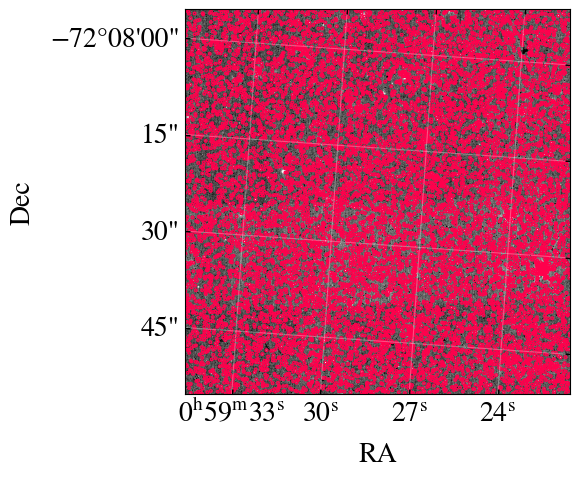

In [ ]:
Image_path = PHOTOMETRIC_pipeline.files.file_paths_1overf_jhat["F115W"][IMAGE_INDEX]

specific_ra_dec = SkyCoord(
    ra=PHOTOMETRIC_pipeline.world_coord_sources["F115W"][IMAGE_INDEX][0] * u.deg,
    dec=PHOTOMETRIC_pipeline.world_coord_sources["F115W"][IMAGE_INDEX][1] * u.deg,
    frame="icrs",
)

target_wcs, shape_out = PLOT.plot_detection_in_frame(
    Image_path=Image_path,
    dra=0 * u.arcmin,
    ddec=0 * u.arcmin,
    rot=4 * u.deg,
    width=1 * u.arcmin,
    height=1 * u.arcmin,
    pix_scale=0.1 * u.arcsec,
    source_coordinates=specific_ra_dec,
    save_name=None,
    tag=False,
)